# Customer Churn Prediction - EDA & Modelling Walkthrough
CodSoft ML Internship, Task 3. This notebook uses the same `src/` modules as `train.py`.

In [1]:
import sys, json
sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display, Markdown
from src.data import load_raw_data, clean_data, data_quality_report
from src.config import FIGURES_DIR, METRICS_PATH

## 1. Load and inspect the data

In [2]:
raw = load_raw_data()
print(raw.shape)
raw.head()

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


## 2. Clean: drop identifiers, check missing values and duplicates

In [5]:
df = clean_data(raw)
q = data_quality_report(df)
{k: q[k] for k in ['rows','columns','total_missing','duplicate_rows','churn_rate','class_counts']}

{'rows': 10000,
 'columns': 11,
 'total_missing': 0,
 'duplicate_rows': 0,
 'churn_rate': 0.2037,
 'class_counts': {'0': 7963, '1': 2037}}

## 3. Categorical & numerical features

In [6]:
for c in ['Geography','Gender']:
    print(df[c].value_counts(), '\n')
df.groupby('Exited')[['CreditScore','Age','Tenure','Balance','NumOfProducts','EstimatedSalary']].mean().T

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64 

Gender
Male      5457
Female    4543
Name: count, dtype: int64 



Exited,0,1
CreditScore,651.853196,645.351497
Age,37.408389,44.837997
Tenure,5.033279,4.932744
Balance,72745.296779,91108.539337
NumOfProducts,1.544267,1.475209
EstimatedSalary,99738.391772,101465.677531


## 4. EDA figures (generated by `src/eda.py`)

**01_churn_distribution.png**

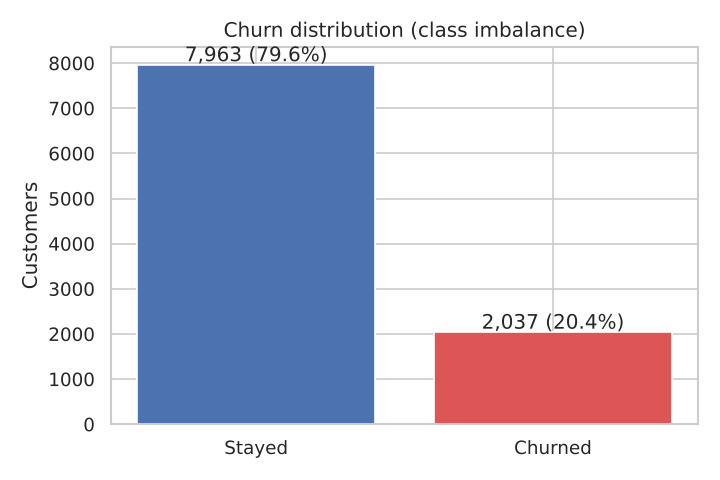

**02_demographics.png**

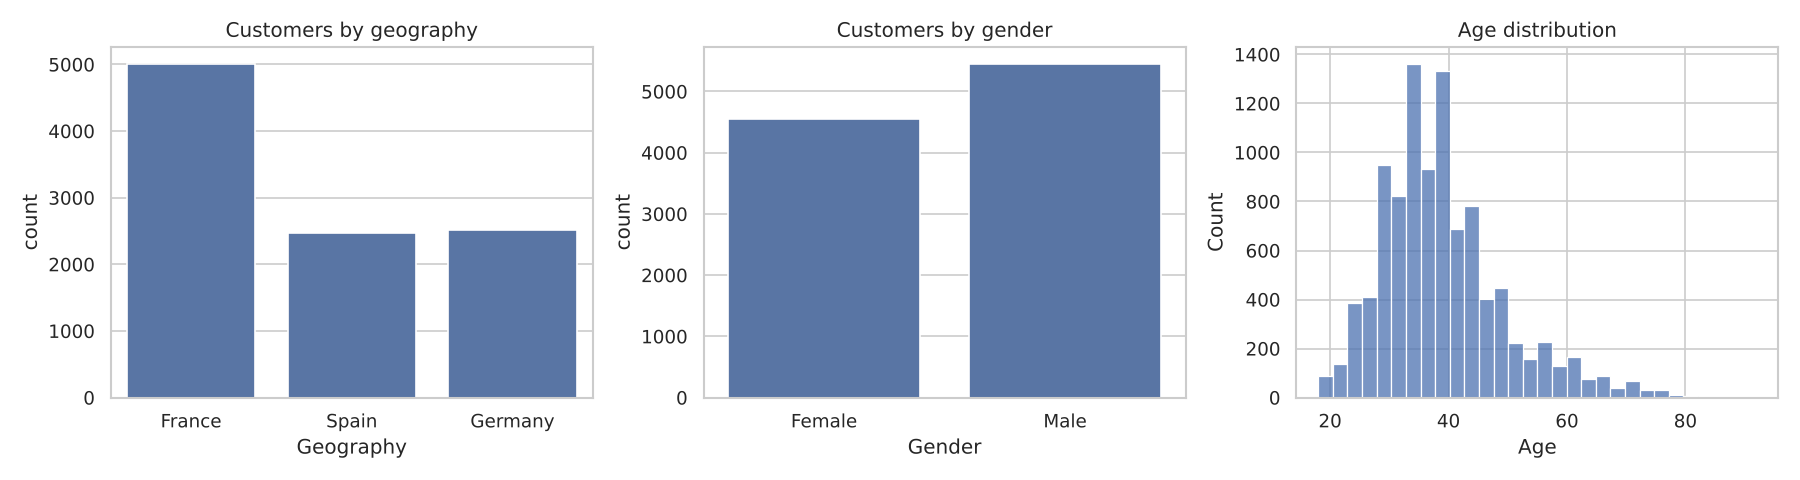

**03_age_vs_churn.png**

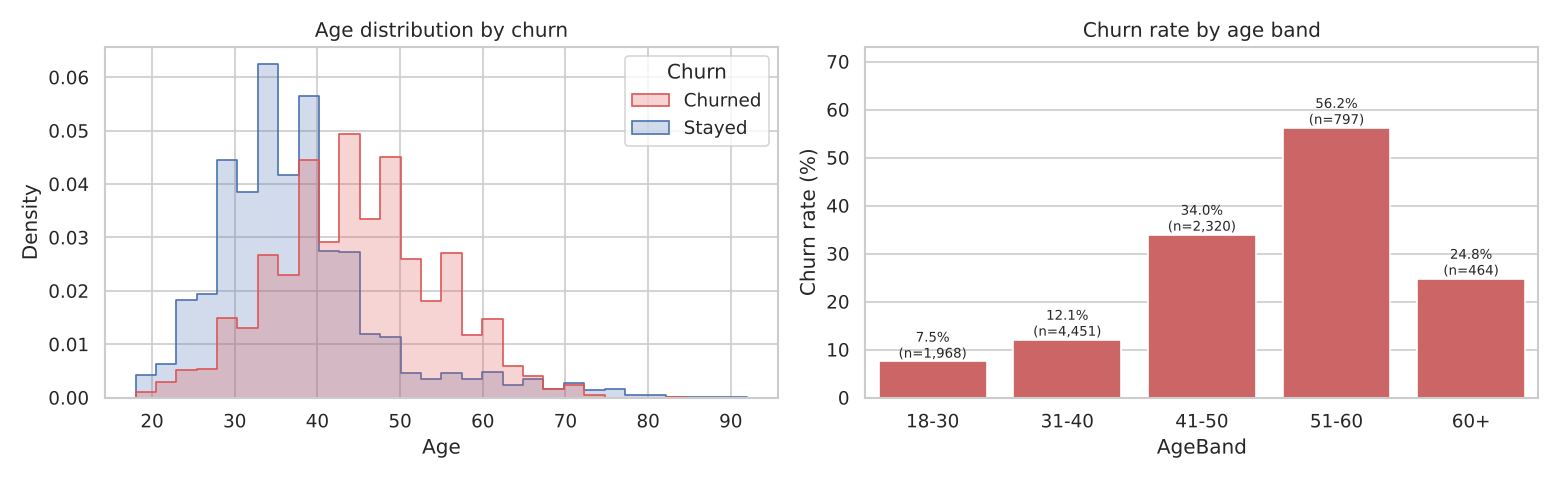

**04_geography_vs_churn.png**

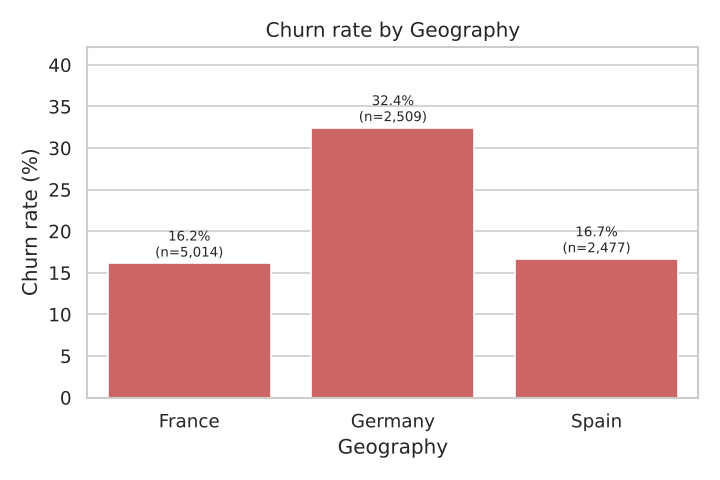

**05_gender_vs_churn.png**

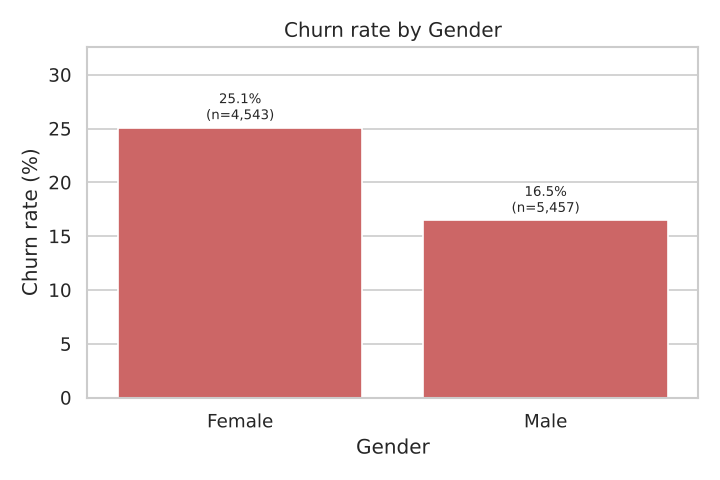

**06_credit_score.png**

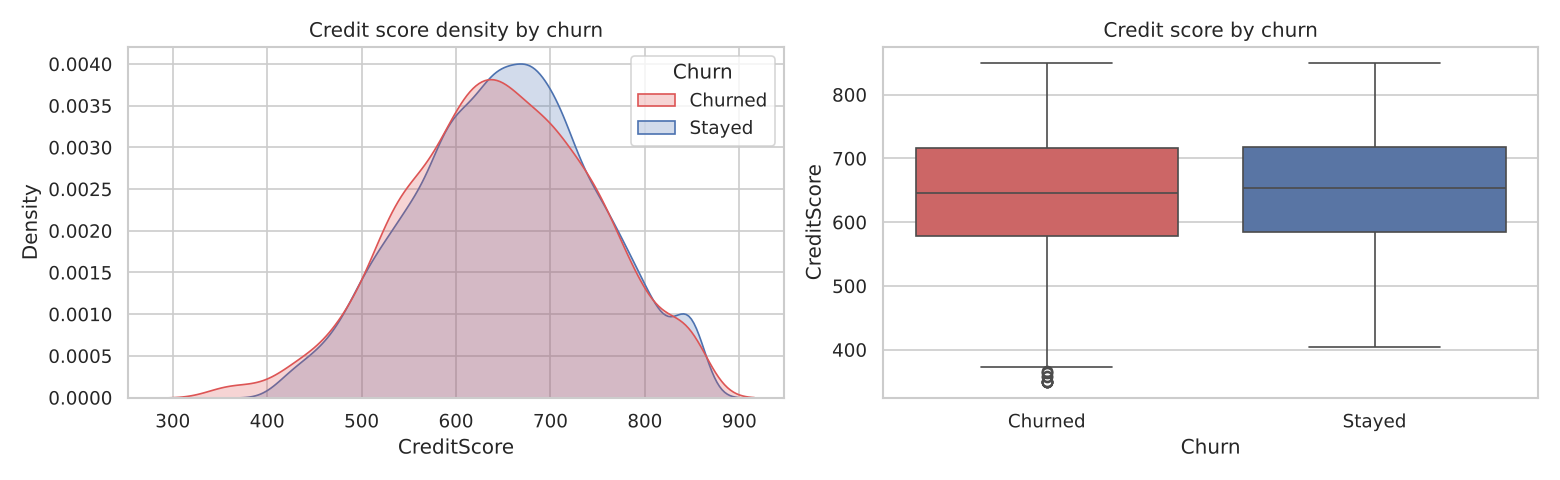

**07_balance_salary.png**

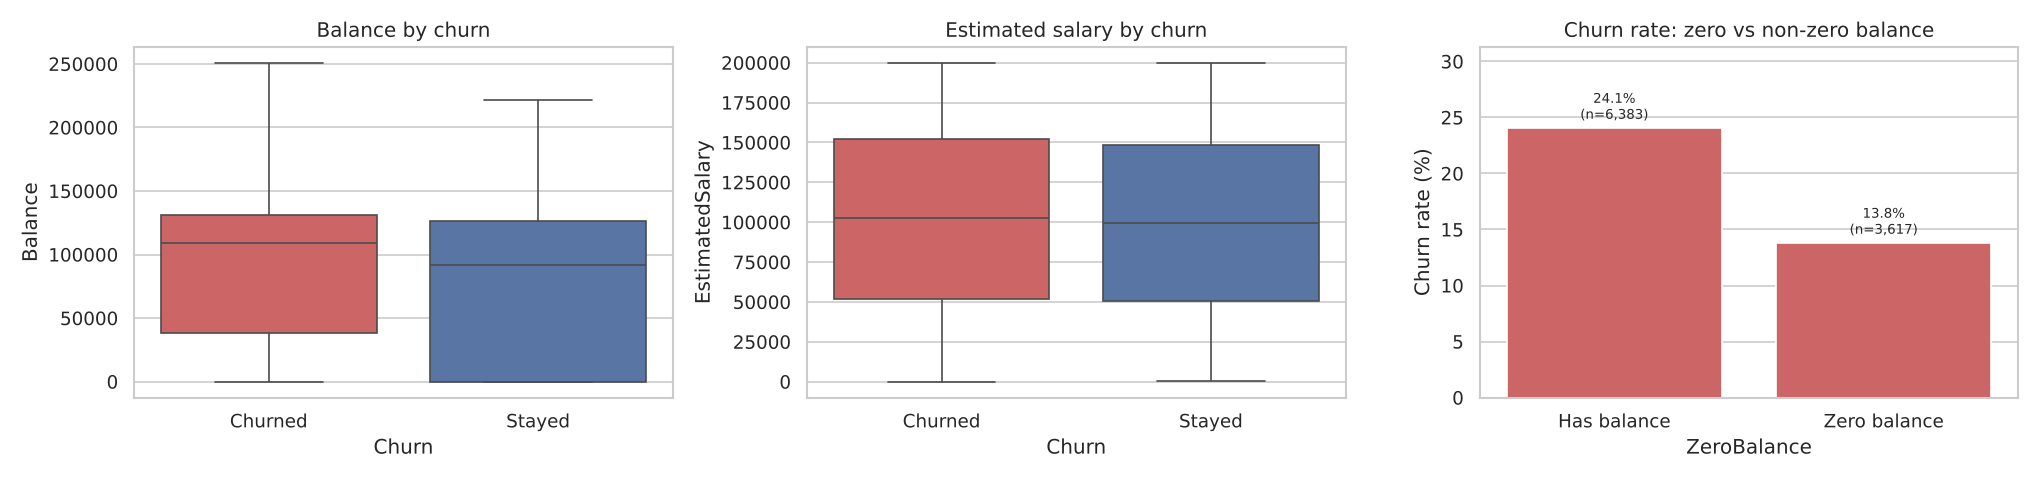

**08_tenure_vs_churn.png**

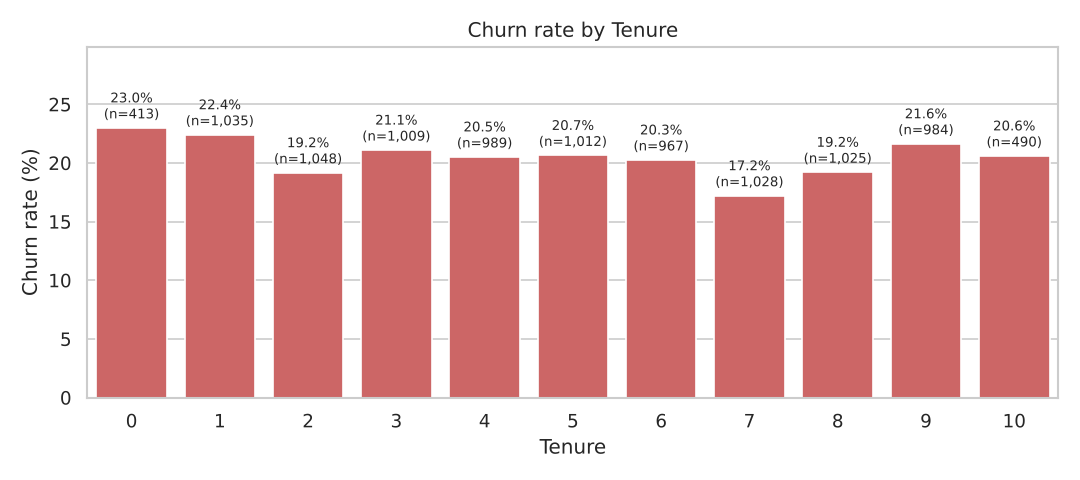

**09_activity_products.png**

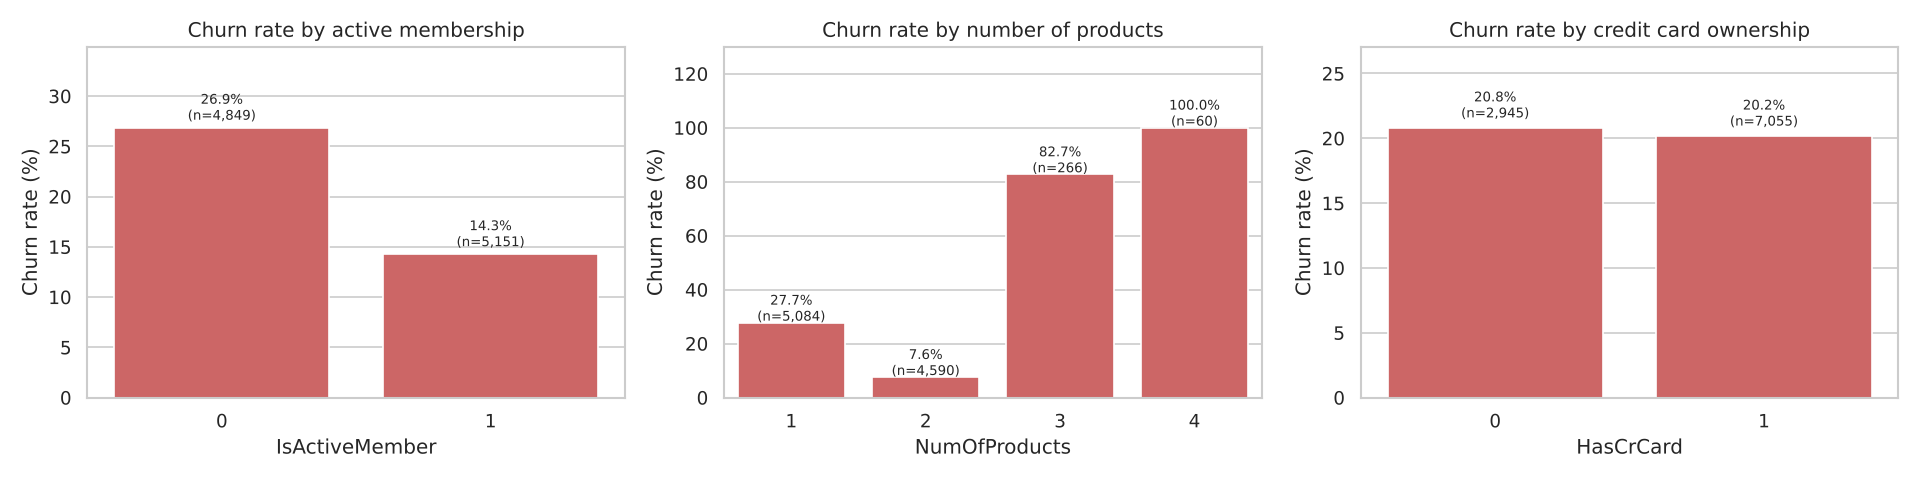

**10_correlation_heatmap.png**

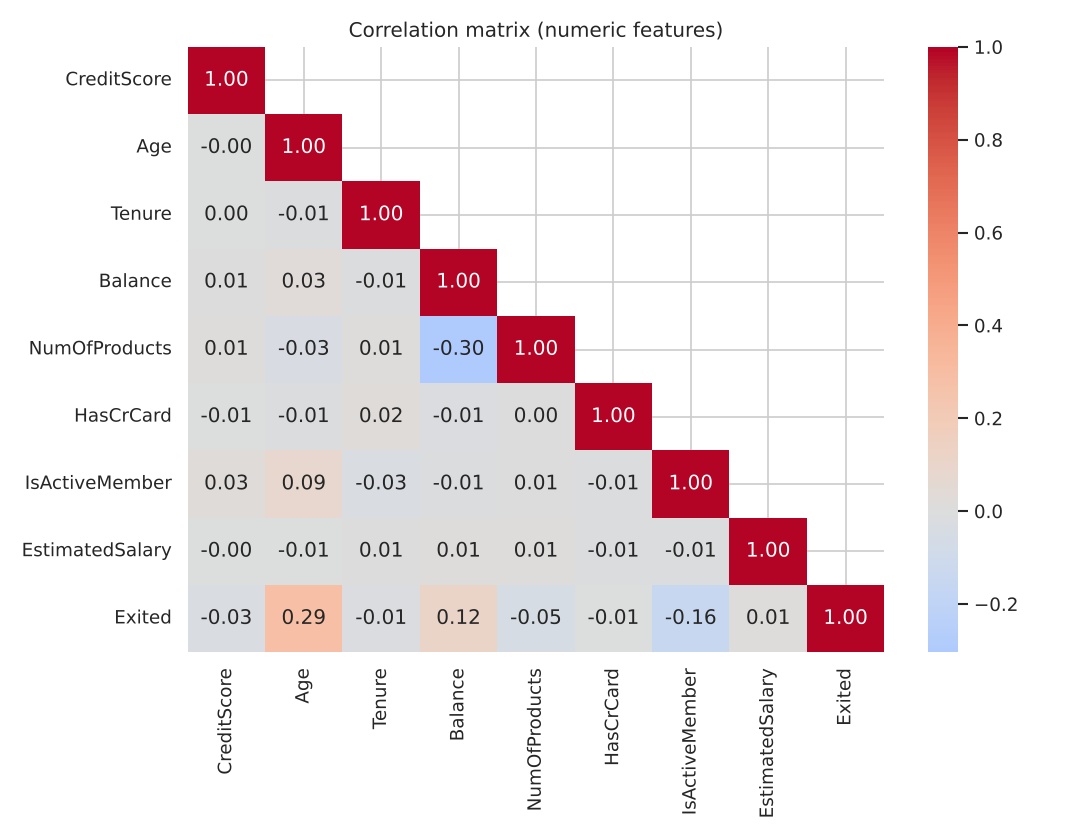

In [7]:
for p in sorted(FIGURES_DIR.glob('*.png'))[:10]:
    display(Markdown(f'**{p.name}**')); display(Image(filename=str(p)))

## 5. Model comparison (results produced by `python train.py`)

In [8]:
m = json.loads(METRICS_PATH.read_text())
rows = {n: {**{f'cv_{k}': v['mean'] for k, v in r['cv'].items() if k != 'best_params'}, **{f'test_{k}': r['test'][k] for k in ['accuracy','precision','recall','f1','roc_auc']}} for n, r in m['models'].items()}
pd.DataFrame(rows).T.round(4)

,cv_f1,cv_recall,cv_precision,cv_roc_auc,cv_accuracy,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
Logistic Regression,0.4932,0.6859,0.3853,0.7673,0.7130,0.7180,0.3926,0.7052,0.5044,0.7771
Random Forest,0.6117,0.6534,0.5759,0.8537,0.8315,0.8320,0.5747,0.6708,0.6190,0.8575
Gradient Boosting,0.6077,0.7190,0.5267,0.8603,0.8111,0.8085,0.5207,0.7420,0.6120,0.8588


In [9]:
print('Selected model:', m['best_model'])
print(m['models'][m['best_model']]['test']['classification_report_text'])

Selected model: Random Forest
              precision    recall  f1-score   support

      Stayed       0.91      0.87      0.89      1593
     Churned       0.57      0.67      0.62       407

    accuracy                           0.83      2000
   macro avg       0.74      0.77      0.76      2000
weighted avg       0.84      0.83      0.84      2000



**11_model_comparison.png**

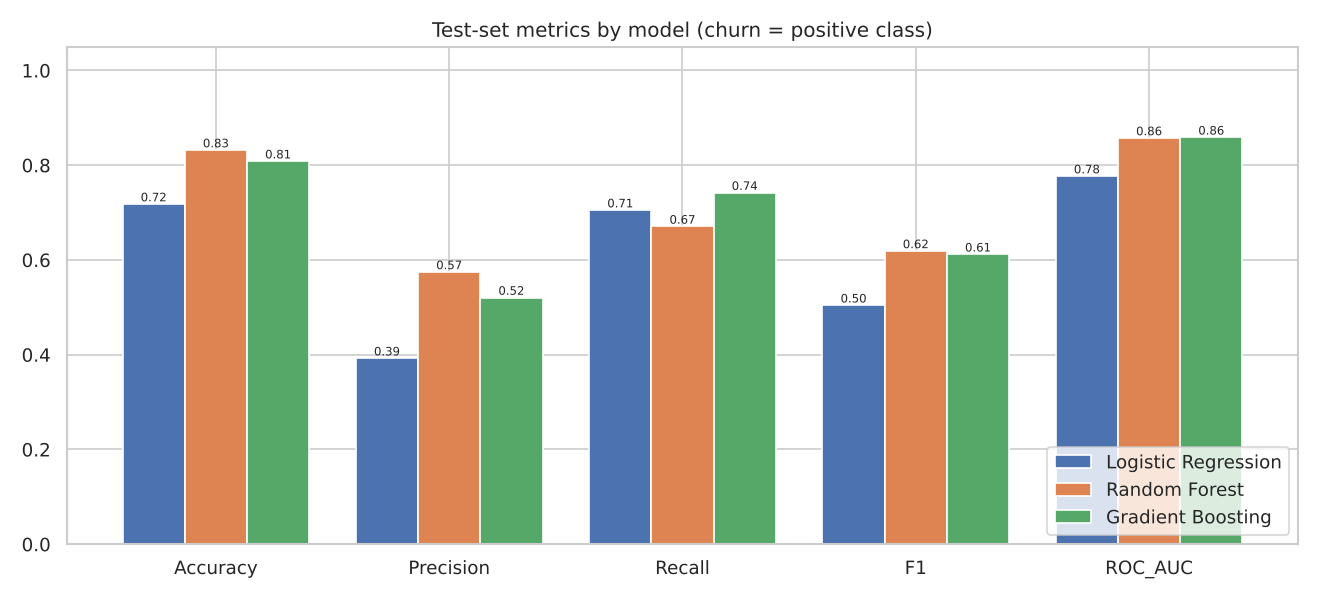

**12_confusion_matrices.png**

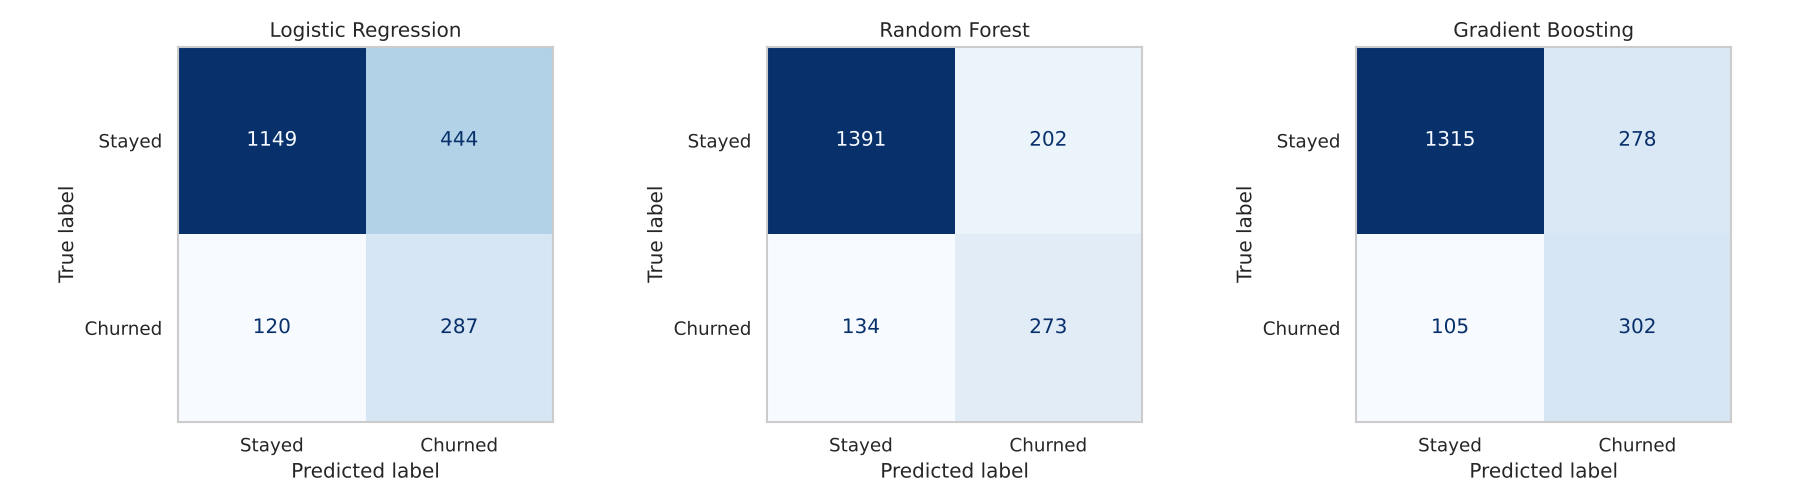

**13_roc_curves.png**

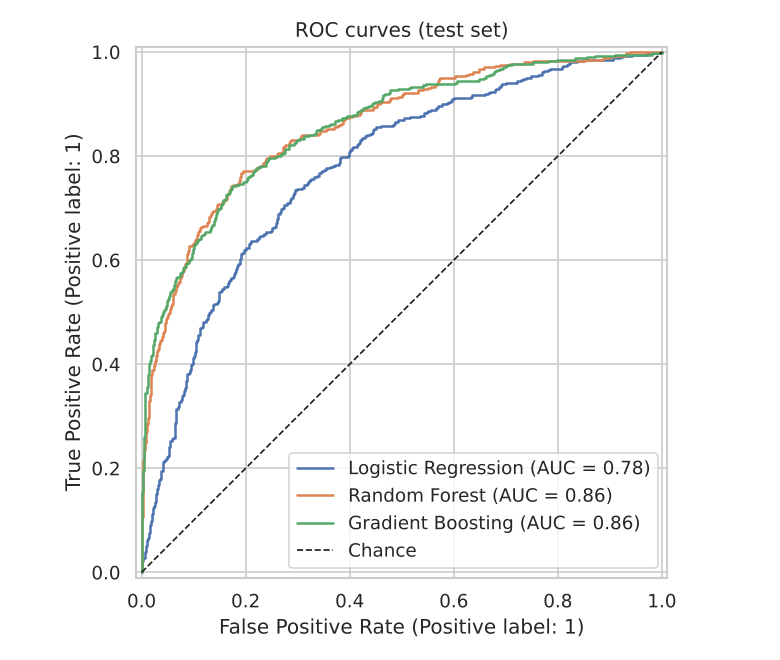

**14_feature_importance.png**

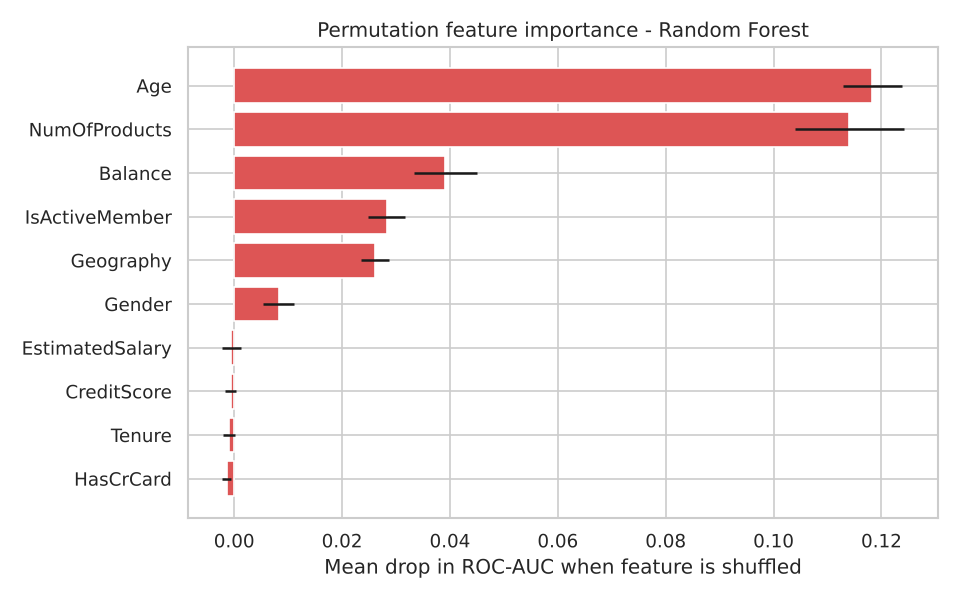

**15_best_model_confusion_matrix.png**

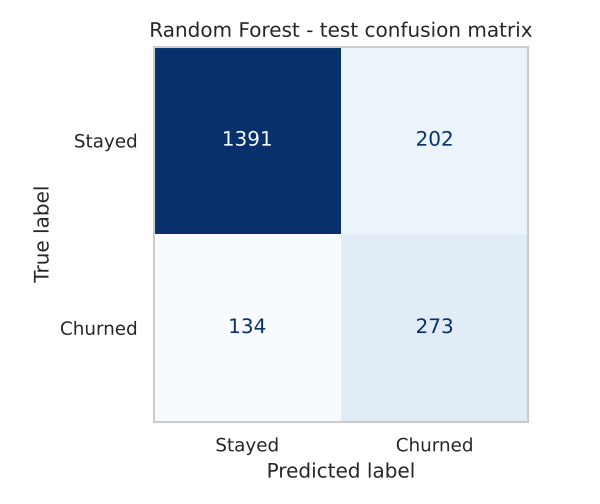

In [10]:
for p in sorted(FIGURES_DIR.glob('1[1-5]_*.png')):
    display(Markdown(f'**{p.name}**')); display(Image(filename=str(p)))